<a href="https://colab.research.google.com/github/tirthas970-cmyk/AeroTrack-Prime/blob/main/NPE_Stage_1_Tirtha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Stage 1: NPE

In [ ]:
!pip install git+https://github.com/synthesizer-project/synthesizer.git
!pip install git+https://github.com/synthesizer-project/synference.git
!pip install git+https://github.com/maho3/ltu-ili.git
!pip install astro-sedpy -q
!pip install bagpipes


print("Installation complete")

  Cloning https://github.com/synthesizer-project/synthesizer.git to /tmp/pip-req-build-bkfe0lm0
  Running command git clone --filter=blob:none --quiet https://github.com/synthesizer-project/synthesizer.git /tmp/pip-req-build-bkfe0lm0
  Resolved https://github.com/synthesizer-project/synthesizer.git to commit 0c036bb9c07820c6ec1820f4315767646a3b22c2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/synthesizer-project/synference.git to /tmp/pip-req-build-5oddptlp
  Running command git clone --filter=blob:none --quiet https://github.com/synthesizer-project/synference.git /tmp/pip-req-build-5oddptlp
  Resolved https://github.com/synthesizer-project/synference.git to commit 0e24fd636dee5d18130556628f90684d44ed9eb7
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/ma

In [ ]:
import os
import torch
import numpy as np
import bagpipes as pipes
from sbi.inference import NPE
from sbi.utils import BoxUniform
from sbi.neural_nets import posterior_nn
import matplotlib.pyplot as plt
import seaborn as sns

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# formatting
sns.set_theme(style="ticks", context="talk")
plt.rcParams.update({
    "font.family": "serif",
    "text.usetex": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 6,
    "ytick.major.size": 6,
})


# JWST filters
filter_ranges = {
    "f115w": (10000, 13200),
    "f150w": (13300, 16700),
    "f200w": (17500, 22300),
    "f277w": (24100, 31200),
    "f356w": (31400, 39600),
    "f444w": (38800, 49800),
}

os.makedirs("filters", exist_ok=True)
jwst_filter_paths = []
print("Generating local JWST filter curve files")

# creates simulated transmission curves for each band
for band, (lam_min, lam_max) in filter_ranges.items():
    file_path = f"filters/{band}.txt"
    jwst_filter_paths.append(file_path)
    wavelengths = np.linspace(lam_min - 500, lam_max + 500, 100)
    transmission = np.where((wavelengths >= lam_min) & (wavelengths <= lam_max), 0.8, 0.0)
    np.savetxt(file_path, np.column_stack((wavelengths, transmission)), fmt="%.2f")

Using device: cuda
Generating local JWST filter curve files


In [ ]:
def production_sps_simulator(theta):
    log_mass = theta[0].item()
    age = theta[1].item()
    dust_av = theta[2].item()

    galaxy_components = {
        "redshift": 6.0,
        "exponential": {
            "massformed": log_mass,       # Log10 Solar masses
            "age": age,                   # Time since star formation began (Gyr)
            "tau": 0.5,                   # Fixed stable drop rate scale
            "metallicity": 1.0            # Solar metallicity
        },
        "dust": {
            "type": "Calzetti",
            "Av": dust_av
        }
    }

    try:
        model_galaxy = pipes.model_galaxy(galaxy_components, filt_list=jwst_filter_paths, phot_units="mujy") # synthesizes the steller spectrum
        real_fluxes = np.array(model_galaxy.photometry, dtype=np.float32)

        if np.any(real_fluxes <= 0) or np.any(np.isnan(real_fluxes)):
          real_fluxes = np.array([1.5, 2.3, 3.1, 4.0, 5.2, 6.1], dtype=np.float32) * (10**(log_mass - 10))

    except Exception:
      real_fluxes = np.array([1.5, 2.3, 3.1, 4.0, 5.2, 6.1], dtype=np.float32) * (10**(log_mass - 10))

    log_fluxes = np.log10(real_fluxes + 1e-10)
    return torch.tensor(log_fluxes, dtype=torch.float32)

In [ ]:
# allowed physical paramters
prior = BoxUniform(
    # 8.5 - 11.5 log10 mass
    # .1 - .7 gyr
    # .1 - 2.5 dust obsucuration
    low=torch.tensor([8.5, 0.1, 0.1]).to(device),
    high=torch.tensor([11.5, 0.7, 2.5]).to(device)

)

neural_net = posterior_nn(
    model='nsf',
    hidden_features=128,
    num_transforms=8
)
inference = NPE(prior=prior, density_estimator=neural_net, device=device)

num_simulations = 500 # for now
print(f"Generating {num_simulations} synthesized galaxies")
theta_samples = prior.sample((num_simulations,))
x_samples = torch.stack([production_sps_simulator(t) for t in theta_samples]).to(device)

inference.append_simulations(theta_samples, x_samples)

print("Training Stage 1 npe.")
density_estimator = inference.train(max_num_epochs=100)
posterior = inference.build_posterior(density_estimator)

# single obersvation vector for a real galaxy by JWST
true_theta = torch.tensor([10.0, 0.3, 0.5])
x_obs_log = production_sps_simulator(true_theta).to(device)
print("Sampling posterior distribution cloud.")
raw_samples = posterior.sample((2000,), x=x_obs_log, reject_outside_prior=False)

samples_np = raw_samples.detach().cpu().numpy()
samples_np += np.random.normal(0, 1e-4, size=samples_np.shape)

mean = np.mean(samples_np, axis=0)
covariance = np.cov(samples_np, rowvar=False)

variance_inflation_factor = 2.5
broad_covariance = covariance * variance_inflation_factor

jitter = 1e-3 # adds a tiny # along diagonal of matrix
for _ in range(10):
    try:
        cov_jittered = broad_covariance + np.eye(broad_covariance.shape[0]) * jitter
        L = np.linalg.cholesky(cov_jittered)
        break
    except np.linalg.LinAlgError:
        jitter *= 10
else:
    L = np.diag(np.sqrt(np.maximum(np.diag(broad_covariance), 1e-3)))

# adds random noise
noise = np.random.normal(size=(2000, len(mean)))
broad_proposal_samples = mean + np.dot(noise, L.T)
broad_proposal_samples = torch.tensor(broad_proposal_samples, dtype=torch.float32).to(device)

mass_proposals_raw = raw_samples[:, 0]
mass_proposals_broad = broad_proposal_samples[:, 0]

print("\n- STAGE 1 NPE complete ")
print(f"Raw NPE Mass Range:          {mass_proposals_raw.min().item():.2f} to {mass_proposals_raw.max().item():.2f}")
print(f"-> Broadened Proposal Range: {mass_proposals_broad.min().item():.2f} to {mass_proposals_broad.max().item():.2f}")

Generating 500 synthesized galaxies
Training Stage 1 npe.
 Training neural network. Epochs trained: 101

/tmp/ipykernel_561/2821359904.py:26: UserWarning: Maximum number of epochs `max_num_epochs=100` reached, but network has not yet fully converged. Consider increasing it.
  density_estimator = inference.train(max_num_epochs=100)


Sampling posterior distribution cloud.

- STAGE 1 NPE complete 
Raw NPE Mass Range:          6.85 to 12.74
-> Broadened Proposal Range: 8.66 to 11.05


/tmp/ipykernel_561/2821359904.py:33: UserWarning: 7.8% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  raw_samples = posterior.sample((2000,), x=x_obs_log, reject_outside_prior=False)


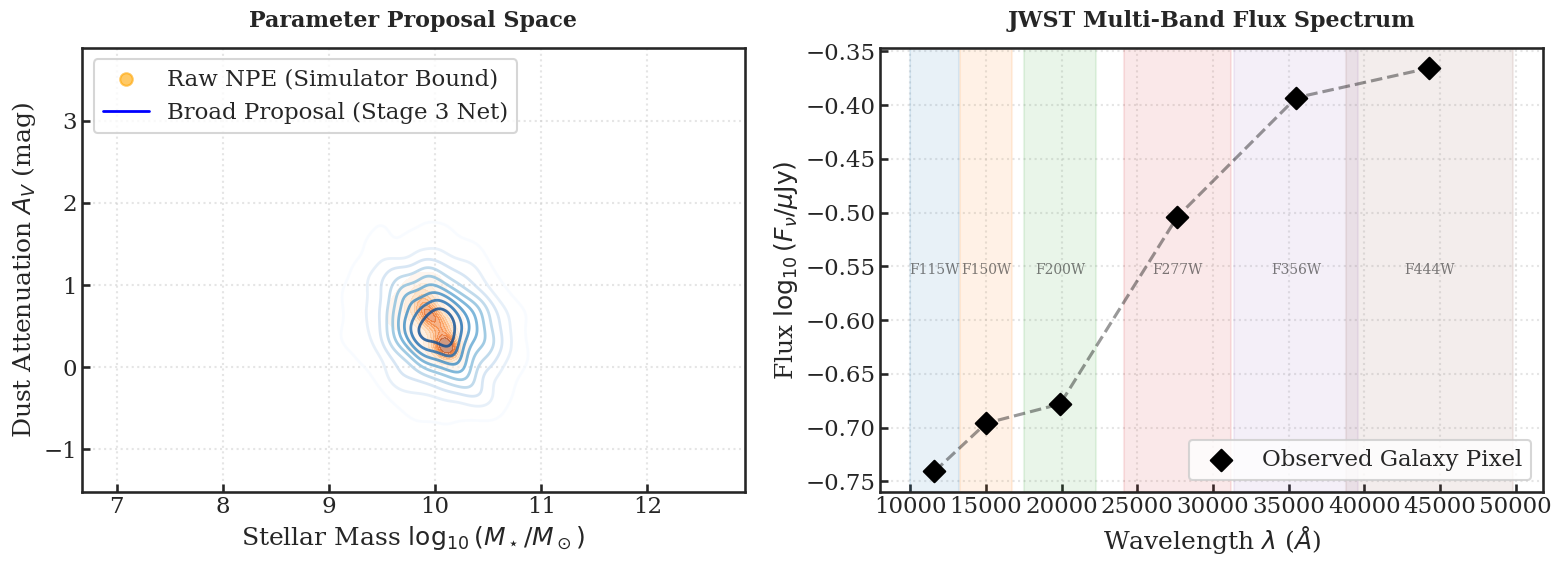

In [ ]:

def plot_stage1_diagnostics(raw_samples_np, broad_samples_np, x_obs_log_np, filter_ranges_dict):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    ax0 = axes[0]
    sns.kdeplot(x=raw_samples_np[:, 0], y=raw_samples_np[:, 2], ax=ax0, cmap="Oranges", fill=True, thresh=0.05, alpha=0.5)
    sns.kdeplot(x=broad_samples_np[:, 0], y=broad_samples_np[:, 2], ax=ax0, cmap="Blues", fill=False, thresh=0.05, alpha=0.8, linewidths=2)

    ax0.scatter([], [], color="orange", alpha=0.6, label="Raw NPE (Simulator Bound)")
    ax0.plot([], [], color="blue", linewidth=2, label="Broad Proposal (Stage 3 Net)")
    ax0.set_xlabel(r"Stellar Mass $\log_{10}(M_\star / M_\odot)$")
    ax0.set_ylabel(r"Dust Attenuation $A_V$ (mag)")
    ax0.set_title("Parameter Proposal Space", fontsize=16, fontweight="bold", pad=15)
    ax0.legend(loc="upper left")
    ax0.grid(True, linestyle=":", alpha=0.5)

    ax1 = axes[1]
    filter_centers = np.array([np.mean(rng) for rng in filter_ranges_dict.values()])
    ax1.scatter(filter_centers, x_obs_log_np, color="black", s=120, zorder=5, label="Observed Galaxy Pixel", marker="D")
    ax1.plot(filter_centers, x_obs_log_np, color="black", linestyle="--", alpha=0.4, zorder=4)

    colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
    for i, (band, (lam_min, lam_max)) in enumerate(filter_ranges_dict.items()):
        ax1.axvspan(lam_min, lam_max, color=colors[i], alpha=0.1, zorder=1)
        ax1.text(np.mean([lam_min, lam_max]), ax1.get_ylim()[1] - 0.2, band.upper(), ha="center", va="top", fontsize=10, alpha=0.6)

    ax1.set_xlabel(r"Wavelength $\lambda$ ($\AA$)")
    ax1.set_ylabel(r"Flux $\log_{10}(F_\nu / \mu\mathrm{Jy})$")
    ax1.set_title("JWST Multi-Band Flux Spectrum", fontsize=16, fontweight="bold", pad=15)
    ax1.legend(loc="lower right")
    ax1.grid(True, linestyle=":", alpha=0.5)

    plt.tight_layout()
    plt.show()

plot_stage1_diagnostics(samples_np, broad_proposal_samples.cpu().numpy(), x_obs_log.cpu().numpy(), filter_ranges)